In [1]:
# Data handling
import os
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering algorithms
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN,
    OPTICS,
    MeanShift
)
from sklearn.mixture import GaussianMixture
from sklearn_extra.cluster import KMedoids

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Dimensionality reduction
from sklearn.decomposition import PCA

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Distance calculations
from sklearn.metrics import pairwise_distances

# Warnings
import warnings
warnings.filterwarnings("ignore")

#### 1. Load Prepared Household Features

Load the original standardized household features and PCA-transformed features prepared in Notebook 05. These two representations will be compared to assess whether dimensionality reduction improves customer clustering.

In [3]:
import os
import pandas as pd
import numpy as np

# Paths to prepared feature files
feature_dir = "../data/processed/dimensionality_reduction"

# Load original standardized household features
household_features_scaled = pd.read_csv(
    os.path.join(feature_dir, "household_features_scaled.csv"),
    index_col=0
)

# Load PCA-transformed household features
household_pca_reduced = pd.read_csv(
    os.path.join(feature_dir, "household_pca_features.csv")
).set_index("household_key")

print("Original standardized features:", household_features_scaled.shape)
print("PCA-transformed features:", household_pca_reduced.shape)

Original standardized features: (2500, 14)
PCA-transformed features: (2500, 6)


#### 2. K-Means Baseline

Fit an initial K-Means model on both the original standardized features and the PCA-transformed features. Use the same number of clusters and random seed for a comparable baseline, which will serve as a reference for later tuning and algorithm comparison.

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Ensure both representations contain the same households in the same order
assert household_features_scaled.index.equals(household_pca_reduced.index), (
    "Household IDs or their ordering differ between the two feature representations."
)

# Exploratory baseline settings
baseline_k = 5
random_state = 42

# K-Means on original standardized features
kmeans_original = KMeans(
    n_clusters=baseline_k,
    init="k-means++",
    n_init=10,
    random_state=random_state
)

labels_original = kmeans_original.fit_predict(household_features_scaled)

# K-Means on PCA-transformed features
kmeans_pca = KMeans(
    n_clusters=baseline_k,
    init="k-means++",
    n_init=10,
    random_state=random_state
)

labels_pca = kmeans_pca.fit_predict(household_pca_reduced)

# Baseline evaluation
print("K-Means Baseline (K=5)")
print("-" * 40)

print("Original features")
print("Inertia:", kmeans_original.inertia_)
print("Silhouette:", silhouette_score(household_features_scaled, labels_original))

print("\nPCA features")
print("Inertia:", kmeans_pca.inertia_)
print("Silhouette:", silhouette_score(household_pca_reduced, labels_pca))

K-Means Baseline (K=5)
----------------------------------------
Original features
Inertia: 18992.797964700687
Silhouette: 0.14314249809310528

PCA features
Inertia: 16763.998903631422
Silhouette: 0.16166345767786847


#### 3. K-Means: Selecting the Number of Clusters

Evaluate K-Means for different values of K on both feature representations using inertia and silhouette scores. Compare the results to identify promising cluster counts for further evaluation.

In [5]:
k_values = range(2, 11)

kmeans_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for k in k_values:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=42
        )

        labels = model.fit_predict(features)

        kmeans_results.append({
            "Representation": representation_name,
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette_score(features, labels)
        })

kmeans_tuning_results = pd.DataFrame(kmeans_results)

display(kmeans_tuning_results.round(4))

,Representation,K,Inertia,Silhouette
0,Original,2,25441.9262,0.2330
1,Original,3,22412.6949,0.1676
2,Original,4,20410.7774,0.1479
3,Original,5,18992.7980,0.1431
4,Original,6,17811.8031,0.1497
5,Original,7,16936.6183,0.1459
6,Original,8,16113.8492,0.1405
7,Original,9,15357.4171,0.1445
8,Original,10,14758.2134,0.1397
9,PCA,2,22925.3164,0.2498


#### 4. Visualising K-Means Tuning Results

Plot inertia and silhouette scores against the number of clusters for both feature representations. These plots will help identify the elbow pattern and compare cluster separation across different values of K.

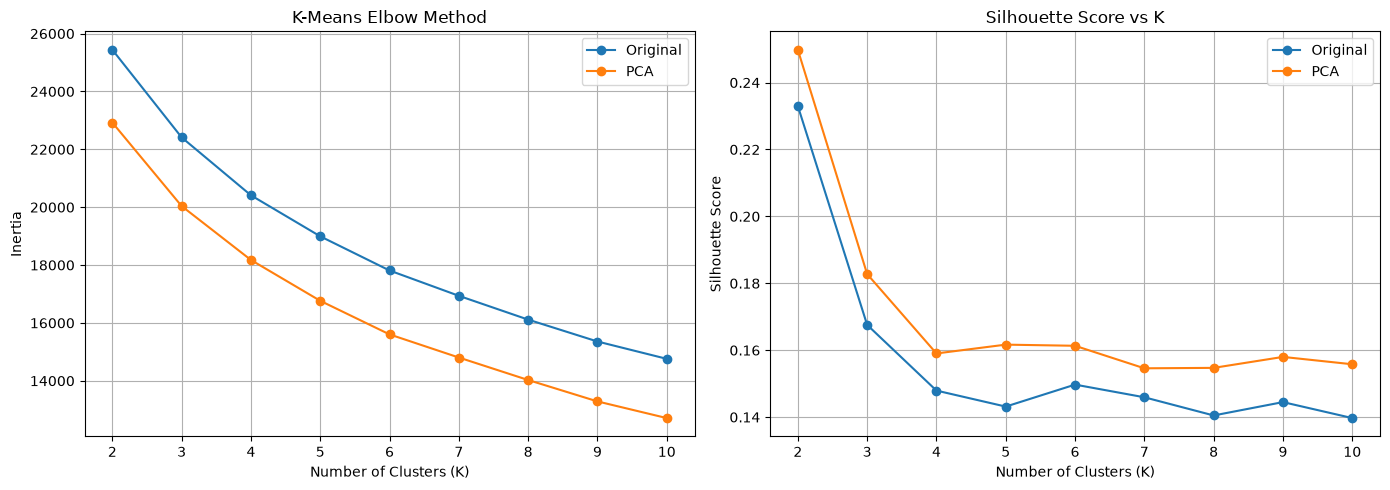

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for representation in ["Original", "PCA"]:
    results = kmeans_tuning_results[
        kmeans_tuning_results["Representation"] == representation
    ]

    axes[0].plot(
        results["K"],
        results["Inertia"],
        marker="o",
        label=representation
    )

    axes[1].plot(
        results["K"],
        results["Silhouette"],
        marker="o",
        label=representation
    )

axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_values)
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_values)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### 5. K-Medoids Clustering

Apply K-Medoids to both feature representations using different candidate cluster counts. Evaluate the resulting clusters using silhouette, Davies-Bouldin and Calinski-Harabasz scores to compare their quality with K-Means.

In [7]:
kmedoids_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for k in [2, 4, 5, 6]:
        model = KMedoids(
            n_clusters=k,
            metric="euclidean",
            method="alternate",
            random_state=42
        )

        labels = model.fit_predict(features)

        kmedoids_results.append({
            "Representation": representation_name,
            "K": k,
            "Silhouette": silhouette_score(features, labels),
            "Davies-Bouldin": davies_bouldin_score(features, labels),
            "Calinski-Harabasz": calinski_harabasz_score(features, labels),
            "Inertia": model.inertia_
        })

kmedoids_results = pd.DataFrame(kmedoids_results)

display(kmedoids_results.round(4))

,Representation,K,Silhouette,Davies-Bouldin,Calinski-Harabasz,Inertia
0,Original,2,0.2275,1.5555,903.8227,7690.2651
1,Original,4,0.1279,1.9626,506.0150,7020.2942
2,Original,5,0.1139,2.0140,414.6703,6898.7837
3,Original,6,0.0929,2.1413,366.1366,6761.2223
4,PCA,2,0.2437,1.4752,1002.0610,7276.7947
5,PCA,4,0.1540,1.8354,573.9732,6491.6785
6,PCA,5,0.0977,1.9208,438.7653,6518.1473
7,PCA,6,0.1205,1.7504,474.9679,6086.5842


#### 6. Agglomerative Hierarchical Clustering

Apply Agglomerative Clustering to both feature representations using different candidate cluster counts. Evaluate the resulting clusters using silhouette, Davies-Bouldin and Calinski-Harabasz scores.

In [8]:
agglomerative_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for k in [2, 4, 5, 6]:
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = model.fit_predict(features)

        agglomerative_results.append({
            "Representation": representation_name,
            "K": k,
            "Silhouette": silhouette_score(features, labels),
            "Davies-Bouldin": davies_bouldin_score(features, labels),
            "Calinski-Harabasz": calinski_harabasz_score(features, labels)
        })

agglomerative_results = pd.DataFrame(agglomerative_results)

display(agglomerative_results.round(4))

,Representation,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Original,2,0.1986,1.6568,745.3698
1,Original,4,0.0933,2.1933,439.9199
2,Original,5,0.0670,2.0776,391.6046
3,Original,6,0.0855,2.0040,364.7617
4,PCA,2,0.2045,1.6343,804.5986
5,PCA,4,0.1074,1.9948,506.8512
6,PCA,5,0.0890,1.9936,446.7585
7,PCA,6,0.0957,1.8949,406.4765


#### 7. Gaussian Mixture Model (GMM)

Fit Gaussian Mixture Models on both feature representations using different candidate component counts. Evaluate cluster quality using silhouette, Davies-Bouldin and Calinski-Harabasz scores, and use AIC and BIC to assess model fit.

In [9]:
gmm_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for k in [2, 4, 5, 6]:
        model = GaussianMixture(
            n_components=k,
            covariance_type="full",
            n_init=5,
            random_state=42
        )

        model.fit(features)
        labels = model.predict(features)

        gmm_results.append({
            "Representation": representation_name,
            "Components": k,
            "Silhouette": silhouette_score(features, labels),
            "Davies-Bouldin": davies_bouldin_score(features, labels),
            "Calinski-Harabasz": calinski_harabasz_score(features, labels),
            "AIC": model.aic(features),
            "BIC": model.bic(features)
        })

gmm_results = pd.DataFrame(gmm_results)

display(gmm_results.round(4))

,Representation,Components,Silhouette,Davies-Bouldin,Calinski-Harabasz,AIC,BIC
0,Original,2,0.2126,1.6277,830.0745,29083.1036,30475.0506
1,Original,4,0.1028,2.0239,501.8248,21006.8793,23796.5973
2,Original,5,0.0786,2.3658,359.0743,10326.3930,13814.9966
3,Original,6,0.0928,2.2411,371.3189,6848.6884,11036.1775
4,PCA,2,0.1340,2.1788,453.0687,49086.2301,49406.5527
5,PCA,4,0.1122,2.5396,273.6767,46446.8725,47093.3416
6,PCA,5,0.0770,2.3585,265.7087,46164.2753,46973.8177
7,PCA,6,0.0614,2.4351,227.6549,46002.7670,46975.3827


#### 8. DBSCAN Clustering

Apply DBSCAN to both feature representations using an initial parameter setting. Evaluate the resulting clusters where valid, while recording the number of clusters and noise points to understand how well DBSCAN identifies dense household groups.

In [23]:
dbscan_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    model = DBSCAN(
        eps=0.5,
        min_samples=5,
        metric="euclidean"
    )

    labels = model.fit_predict(features)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = np.sum(labels == -1)
    valid_mask = labels != -1

    result = {
        "Representation": representation_name,
        "Clusters": n_clusters,
        "Noise Points": noise_count,
        "Noise Fraction": noise_count / len(labels)
    }

    if n_clusters >= 2 and valid_mask.sum() > n_clusters:
        result["Silhouette"] = silhouette_score(
            features[valid_mask],
            labels[valid_mask]
        )
        result["Davies-Bouldin"] = davies_bouldin_score(
            features[valid_mask],
            labels[valid_mask]
        )
        result["Calinski-Harabasz"] = calinski_harabasz_score(
            features[valid_mask],
            labels[valid_mask]
        )
    else:
        result["Silhouette"] = np.nan
        result["Davies-Bouldin"] = np.nan
        result["Calinski-Harabasz"] = np.nan

    dbscan_results.append(result)

dbscan_results = pd.DataFrame(dbscan_results)

display(dbscan_results.round(4))

,Representation,Clusters,Noise Points,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Original,0,2500,1.0,NaN,NaN,NaN
1,PCA,0,2500,1.0,NaN,NaN,NaN


#### 9. OPTICS Clustering

Apply OPTICS to both feature representations using an initial parameter setting. Examine the resulting cluster structure, noise points and clustering metrics to assess its ability to identify groups with varying density.

In [24]:
optics_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    model = OPTICS(
        min_samples=5,
        metric="euclidean",
        cluster_method="xi"
    )

    labels = model.fit_predict(features)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = np.sum(labels == -1)
    valid_mask = labels != -1

    result = {
        "Representation": representation_name,
        "Clusters": n_clusters,
        "Noise Points": noise_count,
        "Noise Fraction": noise_count / len(labels)
    }

    if n_clusters >= 2 and valid_mask.sum() > n_clusters:
        result["Silhouette"] = silhouette_score(
            features[valid_mask],
            labels[valid_mask]
        )
        result["Davies-Bouldin"] = davies_bouldin_score(
            features[valid_mask],
            labels[valid_mask]
        )
        result["Calinski-Harabasz"] = calinski_harabasz_score(
            features[valid_mask],
            labels[valid_mask]
        )
    else:
        result["Silhouette"] = np.nan
        result["Davies-Bouldin"] = np.nan
        result["Calinski-Harabasz"] = np.nan

    optics_results.append(result)

optics_results = pd.DataFrame(optics_results)

display(optics_results.round(4))

,Representation,Clusters,Noise Points,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Original,13,2418,0.9672,0.4095,0.8577,65.8441
1,PCA,29,2311,0.9244,0.4500,0.7472,105.6168


#### 10. Mean Shift Clustering

Apply Mean Shift to both feature representations using an automatically estimated bandwidth. Evaluate the resulting clusters using silhouette, Davies-Bouldin and Calinski-Harabasz scores, while recording the number and sizes of clusters.

In [25]:
from sklearn.cluster import estimate_bandwidth

meanshift_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    bandwidth = estimate_bandwidth(
        features,
        quantile=0.2,
        n_samples=1000,
        random_state=42
    )

    model = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True
    )

    labels = model.fit_predict(features)

    n_clusters = len(np.unique(labels))

    result = {
        "Representation": representation_name,
        "Bandwidth": bandwidth,
        "Clusters": n_clusters,
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan
    }

    if 2 <= n_clusters < len(labels):
        result["Silhouette"] = silhouette_score(features, labels)
        result["Davies-Bouldin"] = davies_bouldin_score(features, labels)
        result["Calinski-Harabasz"] = calinski_harabasz_score(features, labels)

    meanshift_results.append(result)

meanshift_results = pd.DataFrame(meanshift_results)

display(meanshift_results.round(4))

,Representation,Bandwidth,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Original,3.6727,3,0.2703,1.3683,50.1152
1,PCA,3.4580,6,0.1950,1.2991,43.3233


#### 11. Consolidating Baseline Clustering Results

Combine the evaluation results from the completed clustering algorithms into a single comparison table. This provides a consistent overview of cluster quality and coverage before algorithm-specific parameter tuning.

In [26]:
baseline_comparison = pd.concat(
    [
        kmeans_tuning_results.assign(Algorithm="K-Means"),
        kmedoids_results.assign(Algorithm="K-Medoids"),
        agglomerative_results.assign(Algorithm="Agglomerative"),
        gmm_results.rename(columns={"Components": "K"}).assign(
            Algorithm="GMM"
        ),
        dbscan_results.assign(Algorithm="DBSCAN"),
        optics_results.assign(Algorithm="OPTICS"),
        meanshift_results.assign(Algorithm="Mean Shift")
    ],
    ignore_index=True,
    sort=False
)

display(
    baseline_comparison.round(4)
)

,Representation,K,Inertia,Silhouette,Algorithm,Davies-Bouldin,Calinski-Harabasz,AIC,BIC,Clusters,Noise Points,Noise Fraction,Bandwidth
0,Original,2.0,25441.9262,0.2330,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Original,3.0,22412.6949,0.1676,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Original,4.0,20410.7774,0.1479,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Original,5.0,18992.7980,0.1431,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Original,6.0,17811.8031,0.1497,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Original,7.0,16936.6183,0.1459,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Original,8.0,16113.8492,0.1405,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Original,9.0,15357.4171,0.1445,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Original,10.0,14758.2134,0.1397,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PCA,2.0,22925.3164,0.2498,K-Means,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 12. DBSCAN Parameter Tuning

Test different `eps` and `min_samples` values for DBSCAN on the original and PCA features. Record the number of clusters, noise fraction and clustering quality metrics to identify parameter combinations that produce meaningful cluster coverage.

In [27]:
dbscan_tuning_results = []

eps_values = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
min_samples_values = [5, 10, 15]

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for eps in eps_values:
        for min_samples in min_samples_values:

            model = DBSCAN(
                eps=eps,
                min_samples=min_samples,
                metric="euclidean"
            )

            labels = model.fit_predict(features)

            noise_mask = labels == -1
            non_noise_labels = labels[~noise_mask]
            n_clusters = len(np.unique(non_noise_labels))
            noise_fraction = noise_mask.mean()

            result = {
                "Representation": representation_name,
                "eps": eps,
                "min_samples": min_samples,
                "Clusters": n_clusters,
                "Noise Points": noise_mask.sum(),
                "Noise Fraction": noise_fraction,
                "Silhouette": np.nan,
                "Davies-Bouldin": np.nan,
                "Calinski-Harabasz": np.nan
            }

            if n_clusters >= 2 and len(non_noise_labels) > n_clusters:
                non_noise_features = features.loc[~noise_mask]

                result["Silhouette"] = silhouette_score(
                    non_noise_features,
                    non_noise_labels
                )
                result["Davies-Bouldin"] = davies_bouldin_score(
                    non_noise_features,
                    non_noise_labels
                )
                result["Calinski-Harabasz"] = calinski_harabasz_score(
                    non_noise_features,
                    non_noise_labels
                )

            dbscan_tuning_results.append(result)

dbscan_tuning_results = pd.DataFrame(dbscan_tuning_results)

display(
    dbscan_tuning_results.sort_values(
        ["Representation", "Noise Fraction", "Silhouette"],
        ascending=[True, True, False]
    ).round(4)
)

,Representation,eps,min_samples,Clusters,Noise Points,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
18,Original,4.0,5,1,4,0.0016,NaN,NaN,NaN
19,Original,4.0,10,1,7,0.0028,NaN,NaN,NaN
20,Original,4.0,15,1,8,0.0032,NaN,NaN,NaN
15,Original,3.5,5,1,12,0.0048,NaN,NaN,NaN
16,Original,3.5,10,1,13,0.0052,NaN,NaN,NaN
17,Original,3.5,15,1,15,0.0060,NaN,NaN,NaN
12,Original,3.0,5,1,29,0.0116,NaN,NaN,NaN
13,Original,3.0,10,1,35,0.0140,NaN,NaN,NaN
14,Original,3.0,15,1,40,0.0160,NaN,NaN,NaN
9,Original,2.5,5,1,67,0.0268,NaN,NaN,NaN


#### 13. Refining DBSCAN Parameters

Refine the DBSCAN search around the promising parameter ranges identified in the initial experiment. Focus on finding configurations with multiple clusters, reasonable noise fractions and better clustering quality.

In [28]:
dbscan_refined_results = []

refined_parameters = {
    "Original": {
        "eps": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2],
        "min_samples": [5, 10]
    },
    "PCA": {
        "eps": [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6],
        "min_samples": [5, 10]
    }
}

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for eps in refined_parameters[representation_name]["eps"]:
        for min_samples in refined_parameters[representation_name]["min_samples"]:

            labels = DBSCAN(
                eps=eps,
                min_samples=min_samples,
                metric="euclidean"
            ).fit_predict(features)

            noise_mask = labels == -1
            non_noise_labels = labels[~noise_mask]
            n_clusters = len(np.unique(non_noise_labels))

            result = {
                "Representation": representation_name,
                "eps": eps,
                "min_samples": min_samples,
                "Clusters": n_clusters,
                "Noise Points": noise_mask.sum(),
                "Noise Fraction": noise_mask.mean(),
                "Silhouette": np.nan,
                "Davies-Bouldin": np.nan,
                "Calinski-Harabasz": np.nan
            }

            if n_clusters >= 2 and len(non_noise_labels) > n_clusters:
                non_noise_features = features.loc[~noise_mask]

                result["Silhouette"] = silhouette_score(
                    non_noise_features, non_noise_labels
                )
                result["Davies-Bouldin"] = davies_bouldin_score(
                    non_noise_features, non_noise_labels
                )
                result["Calinski-Harabasz"] = calinski_harabasz_score(
                    non_noise_features, non_noise_labels
                )

            dbscan_refined_results.append(result)

dbscan_refined_results = pd.DataFrame(dbscan_refined_results)

display(
    dbscan_refined_results.sort_values(
        ["Representation", "Noise Fraction", "Silhouette"],
        ascending=[True, True, False]
    ).round(4)
)

,Representation,eps,min_samples,Clusters,Noise Points,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
10,Original,1.2,5,13,1411,0.5644,-0.3300,1.2253,6.3186
8,Original,1.1,5,18,1804,0.7216,-0.2150,1.2257,10.5751
11,Original,1.2,10,4,1897,0.7588,-0.1028,1.4379,14.5167
6,Original,1.0,5,20,2186,0.8744,0.0509,1.1856,38.5051
9,Original,1.1,10,7,2242,0.8968,0.1856,1.3114,73.4640
4,Original,0.9,5,7,2434,0.9736,0.2009,1.2115,32.9006
7,Original,1.0,10,2,2479,0.9916,0.4306,0.8841,22.8614
2,Original,0.8,5,1,2495,0.9980,NaN,NaN,NaN
0,Original,0.7,5,0,2500,1.0000,NaN,NaN,NaN
1,Original,0.7,10,0,2500,1.0000,NaN,NaN,NaN


#### 14. OPTICS Parameter Tuning

Test different minimum-neighbour counts, neighbourhood sizes and extraction methods for OPTICS on both feature representations. Compare cluster quality and noise fractions to identify configurations that provide useful coverage.

In [30]:
optics_tuning_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for min_samples in [5, 10, 15]:
        for xi in [0.03, 0.05, 0.07, 0.10]:

            model = OPTICS(
                min_samples=min_samples,
                metric="euclidean",
                cluster_method="xi",
                xi=xi
            )

            labels = model.fit_predict(features)

            noise_mask = labels == -1
            non_noise_labels = labels[~noise_mask]
            n_clusters = len(np.unique(non_noise_labels))

            result = {
                "Representation": representation_name,
                "min_samples": min_samples,
                "xi": xi,
                "Clusters": n_clusters,
                "Noise Points": noise_mask.sum(),
                "Noise Fraction": noise_mask.mean(),
                "Silhouette": np.nan,
                "Davies-Bouldin": np.nan,
                "Calinski-Harabasz": np.nan
            }

            if n_clusters >= 2 and len(non_noise_labels) > n_clusters:
                non_noise_features = features.loc[~noise_mask]

                result["Silhouette"] = silhouette_score(
                    non_noise_features, non_noise_labels
                )
                result["Davies-Bouldin"] = davies_bouldin_score(
                    non_noise_features, non_noise_labels
                )
                result["Calinski-Harabasz"] = calinski_harabasz_score(
                    non_noise_features, non_noise_labels
                )

            optics_tuning_results.append(result)

optics_tuning_results = pd.DataFrame(optics_tuning_results)

display(
    optics_tuning_results.sort_values(
        ["Representation", "Noise Fraction", "Silhouette"],
        ascending=[True, True, False]
    ).round(4)
)

,Representation,min_samples,xi,Clusters,Noise Points,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
5,Original,10,0.05,1,0,0.0000,NaN,NaN,NaN
6,Original,10,0.07,1,0,0.0000,NaN,NaN,NaN
7,Original,10,0.10,1,0,0.0000,NaN,NaN,NaN
8,Original,15,0.03,1,0,0.0000,NaN,NaN,NaN
9,Original,15,0.05,1,0,0.0000,NaN,NaN,NaN
10,Original,15,0.07,1,0,0.0000,NaN,NaN,NaN
11,Original,15,0.10,1,0,0.0000,NaN,NaN,NaN
0,Original,5,0.03,25,2326,0.9304,0.3488,0.9981,65.6104
1,Original,5,0.05,13,2418,0.9672,0.4095,0.8577,65.8441
2,Original,5,0.07,4,2474,0.9896,0.4866,0.7033,107.3705


#### 15. Mean Shift Parameter Tuning

Evaluate Mean Shift using different bandwidth estimates on the original and PCA feature representations. Compare the number of clusters, cluster quality and cluster sizes to identify a suitable bandwidth.

In [31]:
from sklearn.cluster import estimate_bandwidth

meanshift_tuning_results = []

quantile_values = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for quantile in quantile_values:

        bandwidth = estimate_bandwidth(
            features,
            quantile=quantile,
            n_samples=1000,
            random_state=42
        )

        model = MeanShift(
            bandwidth=bandwidth,
            bin_seeding=True
        )

        labels = model.fit_predict(features)

        n_clusters = len(np.unique(labels))

        result = {
            "Representation": representation_name,
            "Quantile": quantile,
            "Bandwidth": bandwidth,
            "Clusters": n_clusters,
            "Silhouette": np.nan,
            "Davies-Bouldin": np.nan,
            "Calinski-Harabasz": np.nan
        }

        if 2 <= n_clusters < len(labels):
            result["Silhouette"] = silhouette_score(features, labels)
            result["Davies-Bouldin"] = davies_bouldin_score(
                features, labels
            )
            result["Calinski-Harabasz"] = calinski_harabasz_score(
                features, labels
            )

        meanshift_tuning_results.append(result)

meanshift_tuning_results = pd.DataFrame(meanshift_tuning_results)

display(
    meanshift_tuning_results.sort_values(
        ["Representation", "Silhouette"],
        ascending=[True, False]
    ).round(4)
)

,Representation,Quantile,Bandwidth,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
2,Original,0.15,3.4321,3,0.2705,1.3751,51.0666
3,Original,0.20,3.6727,3,0.2703,1.3683,50.1152
1,Original,0.10,3.1423,4,0.2147,1.5968,49.8435
0,Original,0.05,2.7314,10,0.1063,1.5697,64.5610
4,Original,0.25,3.8855,1,NaN,NaN,NaN
5,Original,0.30,4.0823,1,NaN,NaN,NaN
10,PCA,0.25,3.6767,3,0.4175,1.3174,28.7130
11,PCA,0.30,3.8778,3,0.4175,1.3174,28.7130
9,PCA,0.20,3.4580,6,0.1950,1.2991,43.3233
8,PCA,0.15,3.2129,9,0.1502,1.2546,37.1032


#### 16. GMM Parameter Tuning

Evaluate Gaussian Mixture Models using different covariance structures and numbers of components on both feature representations. Compare clustering quality alongside AIC and BIC to identify suitable model configurations.

In [10]:
gmm_tuning_results = []

for representation_name, features in [
    ("Original", household_features_scaled),
    ("PCA", household_pca_reduced)
]:
    for n_components in [2, 3, 4, 5, 6]:
        for covariance_type in ["full", "tied", "diag", "spherical"]:

            model = GaussianMixture(
                n_components=n_components,
                covariance_type=covariance_type,
                n_init=5,
                random_state=42
            )

            labels = model.fit_predict(features)

            result = {
                "Representation": representation_name,
                "Components": n_components,
                "Covariance": covariance_type,
                "Silhouette": silhouette_score(features, labels),
                "Davies-Bouldin": davies_bouldin_score(
                    features, labels
                ),
                "Calinski-Harabasz": calinski_harabasz_score(
                    features, labels
                ),
                "AIC": model.aic(features),
                "BIC": model.bic(features)
            }

            gmm_tuning_results.append(result)

gmm_tuning_results = pd.DataFrame(gmm_tuning_results)

display(
    gmm_tuning_results.sort_values(
        ["Representation", "BIC"]
    ).round(4)
)

,Representation,Components,Covariance,Silhouette,Davies-Bouldin,Calinski-Harabasz,AIC,BIC
16,Original,6,full,0.0928,2.2411,371.3189,6848.6884,11036.1775
12,Original,5,full,0.0786,2.3658,359.0743,10326.3930,13814.9966
8,Original,4,full,0.1028,2.0239,501.8248,21006.8793,23796.5973
4,Original,3,full,0.1338,2.0044,616.9955,23332.0238,25422.8563
0,Original,2,full,0.2126,1.6277,830.0745,29083.1036,30475.0506
17,Original,6,tied,0.0576,2.3851,212.0649,30557.7876,31687.6525
13,Original,5,tied,0.1120,1.8742,234.7847,32094.0667,33136.5709
1,Original,2,tied,0.1591,2.0802,479.6552,34220.6814,35001.1036
9,Original,4,tied,0.1709,2.2706,243.4418,36591.7832,37546.9268
5,Original,3,tied,0.1917,1.3719,388.9302,37808.6084,38676.3912


#### 17. Consolidated Clustering Evaluation

Compare the strongest candidate configurations from the clustering experiments using silhouette, Davies-Bouldin and Calinski-Harabasz scores. Include cluster counts and noise fractions wherever applicable, since density-based methods may exclude households as noise.

In [33]:
candidate_evaluation = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Representation": "PCA",
        "Configuration": "K=2",
        "Clusters": 2,
        "Noise Fraction": 0.0,
        "Silhouette": 0.2498,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan
    },
    {
        "Algorithm": "K-Medoids",
        "Representation": "PCA",
        "Configuration": "K=2",
        "Clusters": 2,
        "Noise Fraction": 0.0,
        "Silhouette": 0.2437,
        "Davies-Bouldin": 1.4752,
        "Calinski-Harabasz": 1002.0610
    },
    {
        "Algorithm": "Agglomerative",
        "Representation": "PCA",
        "Configuration": "K=2, Ward",
        "Clusters": 2,
        "Noise Fraction": 0.0,
        "Silhouette": 0.2045,
        "Davies-Bouldin": 1.6343,
        "Calinski-Harabasz": 804.5986
    },
    {
        "Algorithm": "GMM",
        "Representation": "PCA",
        "Configuration": "K=2, spherical",
        "Clusters": 2,
        "Noise Fraction": 0.0,
        "Silhouette": 0.2491,
        "Davies-Bouldin": 1.4351,
        "Calinski-Harabasz": 1035.3928
    },
    {
        "Algorithm": "DBSCAN",
        "Representation": "PCA",
        "Configuration": "eps=1.5, min_samples=5",
        "Clusters": 2,
        "Noise Fraction": 0.1084,
        "Silhouette": 0.2214,
        "Davies-Bouldin": 0.7414,
        "Calinski-Harabasz": 7.4506
    },
    {
        "Algorithm": "OPTICS",
        "Representation": "PCA",
        "Configuration": "min_samples=5, xi=0.07",
        "Clusters": 12,
        "Noise Fraction": 0.9724,
        "Silhouette": 0.5553,
        "Davies-Bouldin": 0.5818,
        "Calinski-Harabasz": 112.8287
    },
    {
        "Algorithm": "Mean Shift",
        "Representation": "PCA",
        "Configuration": "quantile=0.25",
        "Clusters": 3,
        "Noise Fraction": 0.0,
        "Silhouette": 0.4175,
        "Davies-Bouldin": 1.3174,
        "Calinski-Harabasz": 28.7130
    }
])

display(
    candidate_evaluation.sort_values(
        "Silhouette",
        ascending=False
    ).round(4)
)

,Algorithm,Representation,Configuration,Clusters,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
5,OPTICS,PCA,"min_samples=5, xi=0.07",12,0.9724,0.5553,0.5818,112.8287
6,Mean Shift,PCA,quantile=0.25,3,0.0000,0.4175,1.3174,28.7130
0,K-Means,PCA,K=2,2,0.0000,0.2498,NaN,NaN
3,GMM,PCA,"K=2, spherical",2,0.0000,0.2491,1.4351,1035.3928
1,K-Medoids,PCA,K=2,2,0.0000,0.2437,1.4752,1002.0610
4,DBSCAN,PCA,"eps=1.5, min_samples=5",2,0.1084,0.2214,0.7414,7.4506
2,Agglomerative,PCA,"K=2, Ward",2,0.0000,0.2045,1.6343,804.5986


#### 18. Completing K-Means Evaluation Metrics

Calculate the missing Davies-Bouldin and Calinski-Harabasz scores for PCA K-Means with two clusters. Update the consolidated evaluation table so that its comparison metrics are complete.

In [34]:
kmeans_final_eval = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans_final_eval.fit_predict(
    household_pca_reduced
)

kmeans_db = davies_bouldin_score(
    household_pca_reduced,
    kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    household_pca_reduced,
    kmeans_labels
)

candidate_evaluation.loc[
    candidate_evaluation["Algorithm"] == "K-Means",
    "Davies-Bouldin"
] = kmeans_db

candidate_evaluation.loc[
    candidate_evaluation["Algorithm"] == "K-Means",
    "Calinski-Harabasz"
] = kmeans_ch

display(
    candidate_evaluation.sort_values(
        "Silhouette",
        ascending=False
    ).round(4)
)

,Algorithm,Representation,Configuration,Clusters,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz
5,OPTICS,PCA,"min_samples=5, xi=0.07",12,0.9724,0.5553,0.5818,112.8287
6,Mean Shift,PCA,quantile=0.25,3,0.0000,0.4175,1.3174,28.7130
0,K-Means,PCA,K=2,2,0.0000,0.2498,1.4432,1041.2411
3,GMM,PCA,"K=2, spherical",2,0.0000,0.2491,1.4351,1035.3928
1,K-Medoids,PCA,K=2,2,0.0000,0.2437,1.4752,1002.0610
4,DBSCAN,PCA,"eps=1.5, min_samples=5",2,0.1084,0.2214,0.7414,7.4506
2,Agglomerative,PCA,"K=2, Ward",2,0.0000,0.2045,1.6343,804.5986


#### 19. Comparing Cluster Sizes and Balance

Examine the number and proportion of households assigned to each cluster for the leading candidate models. This helps identify whether the models produce balanced segments or are dominated by one large cluster.

In [35]:
cluster_size_results = []

candidate_models = {
    "K-Means": (
        household_pca_reduced,
        KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
    ),
    "GMM": (
        household_pca_reduced,
        GaussianMixture(
            n_components=2,
            covariance_type="spherical",
            n_init=5,
            random_state=42
        )
    ),
    "Mean Shift": (
        household_pca_reduced,
        MeanShift(
            bandwidth=estimate_bandwidth(
                household_pca_reduced,
                quantile=0.25,
                n_samples=1000,
                random_state=42
            ),
            bin_seeding=True
        )
    )
}

for algorithm_name, (features, model) in candidate_models.items():

    labels = (
        model.fit_predict(features)
        if hasattr(model, "fit_predict")
        else model.fit(features).predict(features)
    )

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in counts.items():
        cluster_size_results.append({
            "Algorithm": algorithm_name,
            "Cluster": cluster,
            "Households": count,
            "Percentage": count / len(labels) * 100
        })

cluster_size_results = pd.DataFrame(cluster_size_results)

display(cluster_size_results.round(2))

,Algorithm,Cluster,Households,Percentage
0,K-Means,0,1347,53.88
1,K-Means,1,1153,46.12
2,GMM,0,1408,56.32
3,GMM,1,1092,43.68
4,Mean Shift,0,2483,99.32
5,Mean Shift,1,3,0.12
6,Mean Shift,2,14,0.56


#### 20. Clustering Stability Analysis

Repeat K-Means and GMM clustering with different random initializations and compare their assignments using the Adjusted Rand Index (ARI). Higher ARI values indicate more consistent clustering across runs.

In [36]:
from sklearn.metrics import adjusted_rand_score

stability_results = []

for algorithm_name in ["K-Means", "GMM"]:

    repeated_labels = []

    for seed in range(10):

        if algorithm_name == "K-Means":
            model = KMeans(
                n_clusters=2,
                init="k-means++",
                n_init=1,
                random_state=seed
            )
            labels = model.fit_predict(household_pca_reduced)

        else:
            model = GaussianMixture(
                n_components=2,
                covariance_type="spherical",
                n_init=1,
                random_state=seed
            )
            labels = model.fit_predict(household_pca_reduced)

        repeated_labels.append(labels)

    ari_scores = []

    for i in range(len(repeated_labels)):
        for j in range(i + 1, len(repeated_labels)):
            ari_scores.append(
                adjusted_rand_score(
                    repeated_labels[i],
                    repeated_labels[j]
                )
            )

    stability_results.append({
        "Algorithm": algorithm_name,
        "Mean ARI": np.mean(ari_scores),
        "Minimum ARI": np.min(ari_scores),
        "Maximum ARI": np.max(ari_scores)
    })

stability_results = pd.DataFrame(stability_results)

display(stability_results.round(4))

,Algorithm,Mean ARI,Minimum ARI,Maximum ARI
0,K-Means,0.9913,0.9841,1.0
1,GMM,0.9983,0.9968,1.0


#### 21. Clustering Stability Under Data Perturbation

Introduce small random perturbations to the PCA features and compare the resulting K-Means and GMM assignments with their original assignments using the Adjusted Rand Index. This tests whether the clustering structure remains consistent when the input data changes slightly.

In [37]:
perturbation_results = []

X = household_pca_reduced.to_numpy()

for algorithm_name in ["K-Means", "GMM"]:

    if algorithm_name == "K-Means":
        baseline_model = KMeans(
            n_clusters=2,
            init="k-means++",
            n_init=10,
            random_state=42
        )
        baseline_labels = baseline_model.fit_predict(X)

    else:
        baseline_model = GaussianMixture(
            n_components=2,
            covariance_type="spherical",
            n_init=5,
            random_state=42
        )
        baseline_labels = baseline_model.fit_predict(X)

    for noise_level in [0.01, 0.05, 0.10]:

        perturbed_ari = []

        for seed in range(5):

            rng = np.random.default_rng(seed)

            X_perturbed = X + rng.normal(
                loc=0,
                scale=noise_level,
                size=X.shape
            )

            if algorithm_name == "K-Means":
                model = KMeans(
                    n_clusters=2,
                    init="k-means++",
                    n_init=10,
                    random_state=42
                )
                perturbed_labels = model.fit_predict(X_perturbed)

            else:
                model = GaussianMixture(
                    n_components=2,
                    covariance_type="spherical",
                    n_init=5,
                    random_state=42
                )
                perturbed_labels = model.fit_predict(X_perturbed)

            perturbed_ari.append(
                adjusted_rand_score(
                    baseline_labels,
                    perturbed_labels
                )
            )

        perturbation_results.append({
            "Algorithm": algorithm_name,
            "Noise Level": noise_level,
            "Mean ARI": np.mean(perturbed_ari),
            "Minimum ARI": np.min(perturbed_ari)
        })

perturbation_results = pd.DataFrame(perturbation_results)

display(perturbation_results.round(4))

,Algorithm,Noise Level,Mean ARI,Minimum ARI
0,K-Means,0.01,0.9955,0.9952
1,K-Means,0.05,0.9806,0.9730
2,K-Means,0.10,0.9516,0.9479
3,GMM,0.01,0.9965,0.9920
4,GMM,0.05,0.9837,0.9777
5,GMM,0.10,0.9594,0.9510


#### 22. Cluster-Level Silhouette Analysis

Calculate the average silhouette score for each cluster produced by PCA K-Means and PCA GMM. Compare the cluster-level scores to identify whether both segments are reasonably well separated.

In [38]:
from sklearn.metrics import silhouette_samples

cluster_silhouette_results = []

for algorithm_name, labels in [
    ("K-Means", kmeans_labels),
    ("GMM", GaussianMixture(
        n_components=2,
        covariance_type="spherical",
        n_init=5,
        random_state=42
    ).fit_predict(household_pca_reduced))
]:

    sample_scores = silhouette_samples(
        household_pca_reduced,
        labels
    )

    for cluster in np.unique(labels):
        cluster_mask = labels == cluster

        cluster_silhouette_results.append({
            "Algorithm": algorithm_name,
            "Cluster": cluster,
            "Households": cluster_mask.sum(),
            "Percentage": cluster_mask.mean() * 100,
            "Mean Silhouette": sample_scores[cluster_mask].mean()
        })

cluster_silhouette_results = pd.DataFrame(
    cluster_silhouette_results
)

display(cluster_silhouette_results.round(4))

,Algorithm,Cluster,Households,Percentage,Mean Silhouette
0,K-Means,0,1347,53.88,0.2280
1,K-Means,1,1153,46.12,0.2753
2,GMM,0,1408,56.32,0.2179
3,GMM,1,1092,43.68,0.2893


#### 23. Final Model Selection

Compare PCA K-Means and PCA GMM using clustering quality, cluster balance, initialization stability and perturbation stability. Use these results to select the model that provides the most reliable and practically useful household segmentation.

In [39]:
final_model_comparison = pd.DataFrame([
    {
        "Criterion": "Silhouette",
        "K-Means": 0.2498,
        "GMM": 0.2491,
        "Preferred": "K-Means"
    },
    {
        "Criterion": "Davies-Bouldin",
        "K-Means": 1.4432,
        "GMM": 1.4351,
        "Preferred": "GMM"
    },
    {
        "Criterion": "Calinski-Harabasz",
        "K-Means": 1041.2411,
        "GMM": 1035.3928,
        "Preferred": "K-Means"
    },
    {
        "Criterion": "Mean Initialization ARI",
        "K-Means": 0.9913,
        "GMM": 0.9983,
        "Preferred": "GMM"
    },
    {
        "Criterion": "Mean ARI at 10% Perturbation",
        "K-Means": 0.9516,
        "GMM": 0.9594,
        "Preferred": "GMM"
    }
])

display(final_model_comparison)

,Criterion,K-Means,GMM,Preferred
0,Silhouette,0.2498,0.2491,K-Means
1,Davies-Bouldin,1.4432,1.4351,GMM
2,Calinski-Harabasz,1041.2411,1035.3928,K-Means
3,Mean Initialization ARI,0.9913,0.9983,GMM
4,Mean ARI at 10% Perturbation,0.9516,0.9594,GMM


#### 24. Fitting the Selected GMM Model

Fit the selected two-component spherical GMM on the six-dimensional PCA features. Generate the final household cluster assignments while keeping household identifiers separate from the model inputs.

In [11]:
final_clustering_model = GaussianMixture(
    n_components=2,
    covariance_type="spherical",
    n_init=5,
    random_state=42
)

final_cluster_labels = final_clustering_model.fit_predict(
    household_pca_reduced
)

final_cluster_assignments = pd.DataFrame({
    "household_key": household_pca_reduced.index,
    "cluster": final_cluster_labels
})

display(final_cluster_assignments.head())

print("\nFinal cluster distribution:")
display(
    final_cluster_assignments["cluster"]
    .value_counts()
    .sort_index()
    .rename("Households")
    .to_frame()
)

,household_key,cluster
0,1,1
1,2,0
2,3,0
3,4,0
4,5,0



Final cluster distribution:


,Households
cluster,
0,1408
1,1092


#### 25. Reconstruct Household-Level Profiling Features

Recreate the household-level features using the same transaction source and aggregation definitions from Notebook 05. Join the selected GMM cluster assignments so we can compare the purchasing behaviour of the two segments.

In [41]:
# Load the same transaction columns used in Notebook 05
data_path = "../data/processed/transactions_enriched.csv"

pca_columns = [
    "household_key",
    "BASKET_ID",
    "PRODUCT_ID",
    "QUANTITY",
    "SALES_VALUE",
    "total_discount",
    "estimated_original_value",
    "discount_percentage",
    "COMMODITY_DESC",
    "BRAND"
]

transactions_pca_source = pd.read_csv(
    data_path,
    usecols=pca_columns
)

# Recreate basket-level spending
basket_summary = (
    transactions_pca_source
    .groupby(["household_key", "BASKET_ID"])
    .agg(
        basket_value=("SALES_VALUE", "sum"),
        basket_quantity=("QUANTITY", "sum")
    )
    .reset_index()
)

# Recreate household-level features using Notebook 05 definitions
household_features = (
    transactions_pca_source
    .groupby("household_key")
    .agg(
        transaction_records=("BASKET_ID", "count"),
        unique_baskets=("BASKET_ID", "nunique"),
        unique_products=("PRODUCT_ID", "nunique"),
        unique_categories=("COMMODITY_DESC", "nunique"),
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        average_line_sales=("SALES_VALUE", "mean"),
        average_quantity=("QUANTITY", "mean"),
        multi_unit_share=("QUANTITY", lambda x: (x > 1).mean()),
        total_discount=("total_discount", "sum"),
        discounted_record_share=("total_discount", lambda x: (x > 0).mean()),
        private_brand_share=("BRAND", lambda x: (x == "Private").mean())
    )
)

average_basket_value = (
    basket_summary
    .groupby("household_key")["basket_value"]
    .mean()
    .rename("average_basket_value")
)

household_features = household_features.join(average_basket_value)

household_original_value = (
    transactions_pca_source
    .groupby("household_key")["estimated_original_value"]
    .sum()
)

household_features["discount_percentage"] = (
    household_features["total_discount"]
    / household_original_value.replace(0, np.nan)
    * 100
)

# Attach final GMM cluster assignments
cluster_profile_data = household_features.join(
    final_cluster_assignments.set_index("household_key")["cluster"]
)

print("Household profiling table:", cluster_profile_data.shape)
print("\nCluster coverage:")
display(cluster_profile_data["cluster"].value_counts().sort_index())
display(cluster_profile_data.head())

Household profiling table: (2500, 15)

Cluster coverage:


cluster
0    1408
1    1092
Name: count, dtype: int64

,transaction_records,unique_baskets,unique_products,unique_categories,total_quantity,total_sales,average_line_sales,average_quantity,multi_unit_share,total_discount,discounted_record_share,private_brand_share,average_basket_value,discount_percentage,cluster
household_key,,,,,,,,,,,,,,,
1,1727,86,677,128,1997,4330.16,2.507331,1.156340,0.123335,803.75,0.470759,0.117545,50.350698,15.655709,1
2,714,45,546,141,834,1954.34,2.737171,1.168067,0.114846,343.99,0.460784,0.235294,43.429778,14.966954,0
3,922,47,516,110,8540,2653.21,2.877668,9.262473,0.382863,756.15,0.583514,0.187636,56.451277,22.178649,0
4,301,30,164,63,382,1200.11,3.987076,1.269103,0.186047,118.15,0.431894,0.152824,40.003667,8.962572,0
5,222,40,199,76,245,779.06,3.509279,1.103604,0.094595,118.33,0.531532,0.216216,19.476500,13.186017,0


#### 26. Compare Purchasing Behaviour Across Clusters

Calculate the mean and median of the household-level purchasing features for each GMM cluster. This comparison helps identify differences in spending, purchase frequency, quantity and discount behaviour.

In [42]:
# Select numerical features for cluster profiling
profile_features = [
    "transaction_records",
    "unique_baskets",
    "unique_products",
    "unique_categories",
    "total_quantity",
    "total_sales",
    "average_basket_value",
    "average_line_sales",
    "average_quantity",
    "multi_unit_share",
    "total_discount",
    "discounted_record_share",
    "private_brand_share",
    "discount_percentage"
]

# Calculate mean and median for each cluster
cluster_numeric_profile = (
    cluster_profile_data
    .groupby("cluster")[profile_features]
    .agg(["mean", "median"])
    .round(3)
)

display(cluster_numeric_profile)

transaction_records         unique_baskets        unique_products  \
                       mean  median           mean median            mean   
cluster                                                                     
0                   412.618   362.5         54.393   43.0         272.297   
1                  1845.024  1575.0        183.058  147.0         932.303   

               unique_categories        total_quantity           ...  \
        median              mean median           mean   median  ...   
cluster                                                          ...   
0        261.0            84.588   88.0      16857.693    958.5  ...   
1        837.5           155.302  154.0     216987.170  95684.0  ...   

        multi_unit_share        total_discount           \
                    mean median           mean   median   
cluster                                                   
0                  0.207  0.194        231.429  191.470   
1                  0.207  0.195       1028.094  848.065   

        discounted_record_share        private_brand_share         \
                           mean median                mean median   
cluster                                                             
0                         0.492  0.491               0.291  0.282   
1                         0.513  0.509               0.286  0.281   

        discount_percentage          
                       mean  median  
cluster                              
0                    15.874  15.230  
1                    15.352  14.856  

[2 rows x 28 columns]

#### 27. Detailed Cluster Profile Comparison

Display the complete mean and median values for every household-level feature separately. This allows us to inspect spending, quantity and discount differences without losing columns to output truncation.

In [43]:
for cluster in sorted(cluster_profile_data["cluster"].unique()):
    print(f"\nCLUSTER {cluster}")

    display(
        cluster_profile_data.loc[
            cluster_profile_data["cluster"] == cluster,
            profile_features
        ].agg(["mean", "median"]).T.round(3)
    )


CLUSTER 0


,mean,median
transaction_records,412.618,362.500
unique_baskets,54.393,43.000
unique_products,272.297,261.000
unique_categories,84.588,88.000
total_quantity,16857.693,958.500
total_sales,1202.504,1094.305
average_basket_value,26.791,22.831
average_line_sales,3.117,2.958
average_quantity,69.952,1.466
multi_unit_share,0.207,0.194



CLUSTER 1


,mean,median
transaction_records,1845.024,1575.000
unique_baskets,183.058,147.000
unique_products,932.303,837.500
unique_categories,155.302,154.000
total_quantity,216987.170,95684.000
total_sales,5828.148,4838.825
average_basket_value,37.848,33.271
average_line_sales,3.179,3.074
average_quantity,120.604,68.706
multi_unit_share,0.207,0.195


#### 28. Category Preferences Across Clusters

Compare product-category sales across the two household clusters. Identify the top ten categories in each cluster and calculate their contribution to total cluster sales.

In [44]:
# Attach cluster labels to transaction records
transactions_with_clusters = transactions_pca_source.merge(
    final_cluster_assignments,
    on="household_key",
    how="inner"
)

# Aggregate sales and quantity by cluster and category
category_profile = (
    transactions_with_clusters
    .groupby(["cluster", "COMMODITY_DESC"])
    .agg(
        total_sales=("SALES_VALUE", "sum"),
        total_quantity=("QUANTITY", "sum"),
        transaction_records=("BASKET_ID", "count")
    )
    .reset_index()
)

# Calculate each category's share of its cluster's sales
category_profile["sales_share"] = (
    category_profile["total_sales"]
    / category_profile.groupby("cluster")["total_sales"].transform("sum")
    * 100
)

# Display the top 10 categories in each cluster
top_categories = (
    category_profile
    .sort_values(
        ["cluster", "total_sales"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(10)
    .reset_index(drop=True)
)

display(top_categories.round(3))

,cluster,COMMODITY_DESC,total_sales,total_quantity,transaction_records,sales_share
0,0,SOFT DRINKS,80442.22,41706,29126,4.751
1,0,BEEF,71406.10,15631,11670,4.217
2,0,COUPON/MISC ITEMS,60366.10,22933337,3602,3.565
3,0,FLUID MILK PRODUCTS,47419.00,27734,20712,2.801
4,0,FRZN MEAT/MEAT DINNERS,40684.85,21406,14586,2.403
5,0,CHEESE,39918.95,21028,16233,2.358
6,0,BEERS/ALES,38326.80,5486,4792,2.264
7,0,FROZEN PIZZA,34625.35,16289,10479,2.045
8,0,BAKED BREAD/BUNS/ROLLS,34494.46,24895,20356,2.037
9,0,BAG SNACKS,34432.00,18914,15716,2.034


#### 29. Discount Behaviour Across Clusters

Compare the total discounts, discounted transaction shares and average discount percentages across product categories for both household clusters. This helps identify whether the segments differ in their purchasing response to discounts.

In [45]:
discount_category_profile = (
    transactions_with_clusters
    .groupby(["cluster", "COMMODITY_DESC"])
    .agg(
        total_sales=("SALES_VALUE", "sum"),
        total_discount=("total_discount", "sum"),
        transaction_records=("BASKET_ID", "count"),
        discounted_records=("total_discount", lambda x: (x > 0).sum())
    )
    .reset_index()
)

discount_category_profile["discounted_record_share"] = (
    discount_category_profile["discounted_records"]
    / discount_category_profile["transaction_records"]
    * 100
)

discount_category_profile["discount_to_sales_percentage"] = (
    discount_category_profile["total_discount"]
    / (
        discount_category_profile["total_sales"]
        + discount_category_profile["total_discount"]
    ).replace(0, np.nan)
    * 100
)

display(
    discount_category_profile.sort_values(
        ["cluster", "total_discount"],
        ascending=[True, False]
    ).groupby("cluster").head(10).round(3)
)

,cluster,COMMODITY_DESC,total_sales,total_discount,transaction_records,discounted_records,discounted_record_share,discount_to_sales_percentage
268,0,SOFT DRINKS,80442.22,28851.63,29126,17805,61.131,26.398
25,0,BEEF,71406.10,15037.77,11670,5511,47.224,17.396
53,0,CHICKEN,21129.30,12456.75,4338,2704,62.333,37.089
138,0,FRZN MEAT/MEAT DINNERS,40684.85,12326.87,14586,9325,63.931,23.253
122,0,FLUID MILK PRODUCTS,47419.00,11674.87,20712,10158,49.044,19.756
51,0,CHEESE,39918.95,11431.43,16233,12859,79.215,22.262
165,0,ICE CREAM/MILK/SHERBTS,20605.24,9905.26,7397,5671,76.666,32.465
15,0,BAKED BREAD/BUNS/ROLLS,34494.46,9064.55,20356,14618,71.812,20.810
227,0,PORK,21411.17,8883.20,3434,2082,60.629,29.323
132,0,FROZEN PIZZA,34625.35,7668.11,10479,6661,63.565,18.131



#### 30. Direct Discount Behaviour Comparison Between Clusters

Compare the discounted-record share and discount-to-sales percentage for the same product categories across both clusters. This helps identify differences in discount patterns between the two household segments.


In [46]:

common_discount_categories = set(
    discount_category_profile[
        discount_category_profile["cluster"] == 0
    ]
    .nlargest(10, "total_discount")["COMMODITY_DESC"]
).union(
    discount_category_profile[
        discount_category_profile["cluster"] == 1
    ]
    .nlargest(10, "total_discount")["COMMODITY_DESC"]
)

discount_comparison = (
    discount_category_profile[
        discount_category_profile["COMMODITY_DESC"].isin(
            common_discount_categories
        )
    ]
    .pivot(
        index="COMMODITY_DESC",
        columns="cluster",
        values=[
            "discounted_record_share",
            "discount_to_sales_percentage"
        ]
    )
)

discount_comparison.columns = [
    f"{metric}_cluster_{cluster}"
    for metric, cluster in discount_comparison.columns
]

discount_comparison = discount_comparison.reset_index()

discount_comparison["discounted_share_difference"] = (
    discount_comparison["discounted_record_share_cluster_1"]
    - discount_comparison["discounted_record_share_cluster_0"]
)

discount_comparison["discount_percentage_difference"] = (
    discount_comparison["discount_to_sales_percentage_cluster_1"]
    - discount_comparison["discount_to_sales_percentage_cluster_0"]
)

display(
    discount_comparison.sort_values(
        "discount_percentage_difference",
        ascending=False
    ).round(3)
)


,COMMODITY_DESC,discounted_record_share_cluster_0,discounted_record_share_cluster_1,discount_to_sales_percentage_cluster_0,discount_to_sales_percentage_cluster_1,discounted_share_difference,discount_percentage_difference
3,CHICKEN,62.333,70.448,37.089,39.247,8.116,2.158
8,PORK,60.629,61.553,29.323,29.614,0.924,0.291
5,FROZEN PIZZA,63.565,66.846,18.131,18.262,3.281,0.131
7,ICE CREAM/MILK/SHERBTS,76.666,81.678,32.465,32.326,5.012,-0.139
1,BEEF,47.224,48.872,17.396,17.125,1.648,-0.271
6,FRZN MEAT/MEAT DINNERS,63.931,69.104,23.253,22.819,5.173,-0.434
0,BAKED BREAD/BUNS/ROLLS,71.812,72.971,20.810,20.244,1.159,-0.566
4,FLUID MILK PRODUCTS,49.044,49.677,19.756,18.461,0.632,-1.296
2,CHEESE,79.215,80.335,22.262,20.955,1.120,-1.306
9,SOFT DRINKS,61.131,66.186,26.398,25.062,5.055,-1.336



#### 31. Visualise Final Customer Clusters in 2D PCA Space

Project the six-dimensional PCA features onto their first two principal components for visualisation. Colour each household according to its final GMM cluster assignment; this is an exploratory view of the clusters, not a new clustering step.


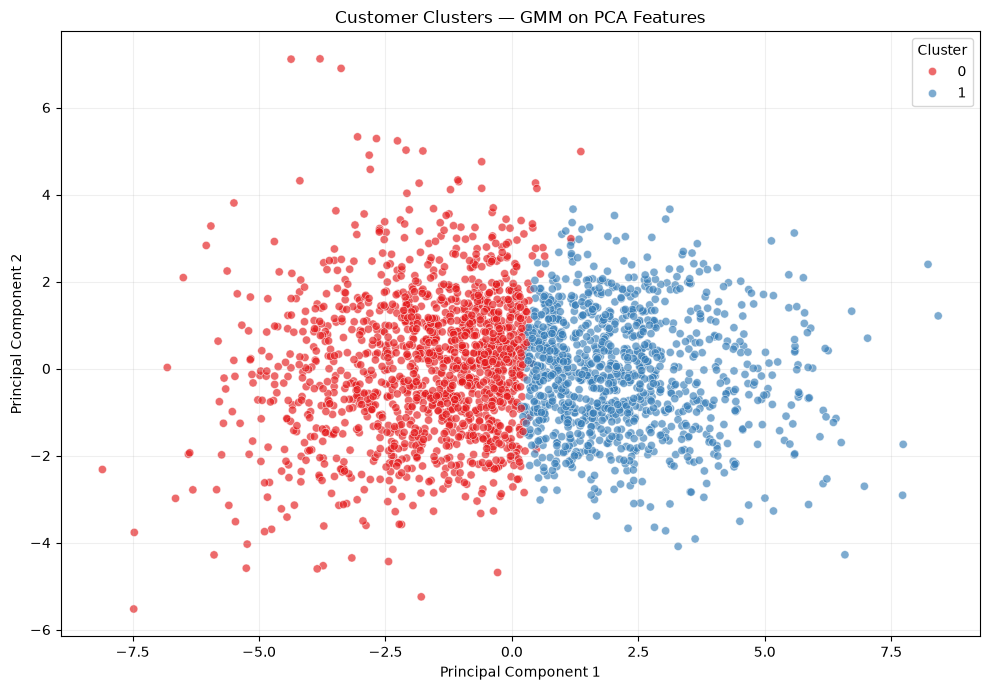

In [47]:

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=household_pca_reduced.iloc[:, 0],
    y=household_pca_reduced.iloc[:, 1],
    hue=final_cluster_assignments["cluster"].values,
    palette="Set1",
    alpha=0.65,
    s=35
)

plt.title("Customer Clusters — GMM on PCA Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



#### 32. Create Output Directory and Save Core Clustering Results

Create the output directory and save the final household assignments, K-Means tuning results and consolidated clustering evaluation. These files preserve the main results needed for the project analysis.


In [48]:

# Create output directory
output_dir = "../data/processed/customer_clustering"
os.makedirs(output_dir, exist_ok=True)

# Save final household cluster assignments
final_cluster_assignments.to_csv(
    os.path.join(output_dir, "household_cluster_assignments.csv"),
    index=False
)

# Save K-Means elbow and silhouette results
kmeans_tuning_results.to_csv(
    os.path.join(output_dir, "kmeans_elbow_results.csv"),
    index=False
)

# Save consolidated clustering evaluation
candidate_evaluation.to_csv(
    os.path.join(output_dir, "clustering_evaluation.csv"),
    index=False
)

# Save algorithm comparison
candidate_evaluation.to_csv(
    os.path.join(output_dir, "clustering_comparison.csv"),
    index=False
)

print("Core clustering results saved successfully.")
print("Output directory:", output_dir)


Core clustering results saved successfully.
Output directory: ../data/processed/customer_clustering



#### 33. Generate and Save Cluster Profiles

Calculate the mean and median of each household feature for both clusters. These profiles will help describe the purchasing behaviour of each customer segment.


In [49]:

cluster_profiles = (
    cluster_profile_data
    .drop(columns=["cluster"])
    .groupby(cluster_profile_data["cluster"])
    .agg(["mean", "median"])
)

cluster_profiles.columns = [
    f"{feature}_{statistic}"
    for feature, statistic in cluster_profiles.columns
]

cluster_profiles = cluster_profiles.reset_index()

cluster_profiles.to_csv(
    os.path.join(output_dir, "cluster_profiles.csv"),
    index=False
)

display(cluster_profiles.round(3))
print("Cluster profiles saved successfully.")


,cluster,transaction_records_mean,transaction_records_median,unique_baskets_mean,unique_baskets_median,unique_products_mean,unique_products_median,unique_categories_mean,unique_categories_median,total_quantity_mean,...,total_discount_mean,total_discount_median,discounted_record_share_mean,discounted_record_share_median,private_brand_share_mean,private_brand_share_median,average_basket_value_mean,average_basket_value_median,discount_percentage_mean,discount_percentage_median
0,0,412.618,362.5,54.393,43.0,272.297,261.0,84.588,88.0,16857.693,...,231.429,191.470,0.492,0.491,0.291,0.282,26.791,22.831,15.874,15.230
1,1,1845.024,1575.0,183.058,147.0,932.303,837.5,155.302,154.0,216987.170,...,1028.094,848.065,0.513,0.509,0.286,0.281,37.848,33.271,15.352,14.856


Cluster profiles saved successfully.



#### 34. Save Final Cluster Visualisation

Recreate the final 2D PCA cluster plot and save it as an image in the customer clustering output directory. This preserves the visual result for the final project report.


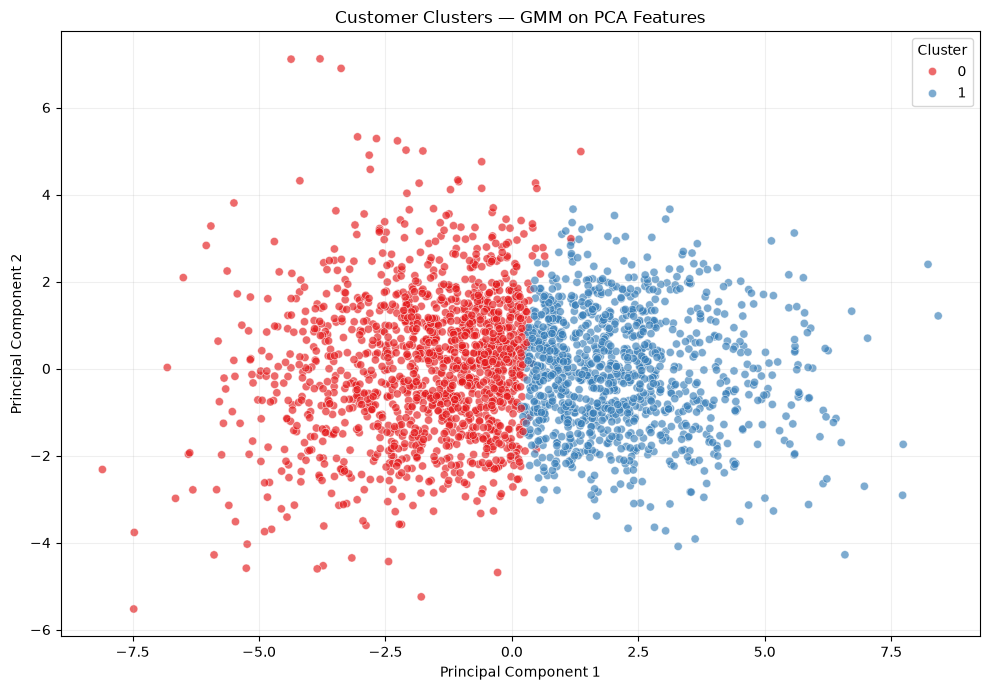

Cluster visualisation saved successfully.


In [50]:

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=household_pca_reduced.iloc[:, 0],
    y=household_pca_reduced.iloc[:, 1],
    hue=final_cluster_assignments["cluster"].values,
    palette="Set1",
    alpha=0.65,
    s=35
)

plt.title("Customer Clusters — GMM on PCA Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "cluster_visualization.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Cluster visualisation saved successfully.")



#### 35. Save Clustering Transformation Decisions

Record the feature representation and dimensionality-reduction decisions used in the final clustering model. This documents why PCA features were selected instead of the original standardized features.


In [51]:

transformation_decisions = pd.DataFrame([
    {
        "decision": "Original feature representation",
        "choice": "14 standardized household features",
        "reason": "Preserves the original household purchasing features."
    },
    {
        "decision": "PCA representation",
        "choice": "6 principal components",
        "reason": "Retains 92.80% of the variance while reducing dimensionality."
    },
    {
        "decision": "Final clustering representation",
        "choice": "PCA features",
        "reason": "Provided slightly better separation for the selected GMM model."
    },
    {
        "decision": "Final clustering algorithm",
        "choice": "Gaussian Mixture Model",
        "reason": "Selected with 2 components and spherical covariance due to its stability and slightly better Davies-Bouldin score."
    }
])

transformation_decisions.to_csv(
    os.path.join(
        output_dir,
        "clustering_transformation_decisions.csv"
    ),
    index=False
)

display(transformation_decisions)
print("Clustering transformation decisions saved successfully.")


,decision,choice,reason
0,Original feature representation,14 standardized household features,Preserves the original household purchasing fe...
1,PCA representation,6 principal components,Retains 92.80% of the variance while reducing ...
2,Final clustering representation,PCA features,Provided slightly better separation for the se...
3,Final clustering algorithm,Gaussian Mixture Model,Selected with 2 components and spherical covar...


Clustering transformation decisions saved successfully.



#### 36. Review Saved Clustering Output Files

Load the saved CSV files and inspect their dimensions, columns and contents. Check whether the clustering evaluation and comparison files are identical, so we can correct any duplication before finalising the outputs.


In [52]:

output_files = [
    "household_cluster_assignments.csv",
    "cluster_profiles.csv",
    "clustering_evaluation.csv",
    "kmeans_elbow_results.csv",
    "clustering_comparison.csv",
    "clustering_transformation_decisions.csv"
]

loaded_outputs = {}

for filename in output_files:
    file_path = os.path.join(output_dir, filename)

    if os.path.exists(file_path):
        loaded_outputs[filename] = pd.read_csv(file_path)
        print(
            f"{filename}: "
            f"{loaded_outputs[filename].shape} | "
            f"Columns: {list(loaded_outputs[filename].columns)}"
        )
    else:
        print(f"MISSING: {filename}")

evaluation_df = loaded_outputs.get("clustering_evaluation.csv")
comparison_df = loaded_outputs.get("clustering_comparison.csv")

if evaluation_df is not None and comparison_df is not None:
    print(
        "\nEvaluation and comparison files identical:",
        evaluation_df.equals(comparison_df)
    )

print("\nAll available saved outputs loaded for inspection.")


household_cluster_assignments.csv: (2500, 2) | Columns: ['household_key', 'cluster']
cluster_profiles.csv: (2, 29) | Columns: ['cluster', 'transaction_records_mean', 'transaction_records_median', 'unique_baskets_mean', 'unique_baskets_median', 'unique_products_mean', 'unique_products_median', 'unique_categories_mean', 'unique_categories_median', 'total_quantity_mean', 'total_quantity_median', 'total_sales_mean', 'total_sales_median', 'average_line_sales_mean', 'average_line_sales_median', 'average_quantity_mean', 'average_quantity_median', 'multi_unit_share_mean', 'multi_unit_share_median', 'total_discount_mean', 'total_discount_median', 'discounted_record_share_mean', 'discounted_record_share_median', 'private_brand_share_mean', 'private_brand_share_median', 'average_basket_value_mean', 'average_basket_value_median', 'discount_percentage_mean', 'discount_percentage_median']
clustering_evaluation.csv: (7, 8) | Columns: ['Algorithm', 'Representation', 'Configuration', 'Clusters', 'Noise


#### 37. Create a Separate Clustering Algorithm Comparison

Keep the original evaluation metrics unchanged and create a separate comparison table by ranking the algorithms on silhouette, Davies-Bouldin, Calinski-Harabasz and noise fraction. This makes the comparison file distinct while preserving the individual evaluation results.


In [53]:

clustering_comparison = candidate_evaluation.copy()

clustering_comparison["silhouette_rank"] = (
    clustering_comparison["Silhouette"]
    .rank(ascending=False, method="min")
)

clustering_comparison["davies_bouldin_rank"] = (
    clustering_comparison["Davies-Bouldin"]
    .rank(ascending=True, method="min")
)

clustering_comparison["calinski_harabasz_rank"] = (
    clustering_comparison["Calinski-Harabasz"]
    .rank(ascending=False, method="min")
)

clustering_comparison["noise_fraction_rank"] = (
    clustering_comparison["Noise Fraction"]
    .rank(ascending=True, method="min")
)

clustering_comparison.to_csv(
    os.path.join(output_dir, "clustering_comparison.csv"),
    index=False
)

display(
    clustering_comparison.sort_values(
        "silhouette_rank"
    ).round(4)
)

print("Separate clustering comparison saved successfully.")


,Algorithm,Representation,Configuration,Clusters,Noise Fraction,Silhouette,Davies-Bouldin,Calinski-Harabasz,silhouette_rank,davies_bouldin_rank,calinski_harabasz_rank,noise_fraction_rank
5,OPTICS,PCA,"min_samples=5, xi=0.07",12,0.9724,0.5553,0.5818,112.8287,1.0,1.0,5.0,7.0
6,Mean Shift,PCA,quantile=0.25,3,0.0000,0.4175,1.3174,28.7130,2.0,3.0,6.0,1.0
0,K-Means,PCA,K=2,2,0.0000,0.2498,1.4432,1041.2411,3.0,5.0,1.0,1.0
3,GMM,PCA,"K=2, spherical",2,0.0000,0.2491,1.4351,1035.3928,4.0,4.0,2.0,1.0
1,K-Medoids,PCA,K=2,2,0.0000,0.2437,1.4752,1002.0610,5.0,6.0,3.0,1.0
4,DBSCAN,PCA,"eps=1.5, min_samples=5",2,0.1084,0.2214,0.7414,7.4506,6.0,2.0,7.0,6.0
2,Agglomerative,PCA,"K=2, Ward",2,0.0000,0.2045,1.6343,804.5986,7.0,7.0,4.0,1.0


Separate clustering comparison saved successfully.



#### 38. Validate All Saved Clustering Deliverables

Check that all seven planned output files exist, verify that the evaluation and comparison files are now different, and confirm that the saved household assignments contain all 2,500 households with the expected cluster distribution.


In [54]:

expected_files = [
    "household_cluster_assignments.csv",
    "cluster_profiles.csv",
    "clustering_evaluation.csv",
    "kmeans_elbow_results.csv",
    "clustering_comparison.csv",
    "cluster_visualization.png",
    "clustering_transformation_decisions.csv"
]

print("OUTPUT FILE VALIDATION")
print("-" * 50)

for filename in expected_files:
    file_path = os.path.join(output_dir, filename)
    print(f"{filename}: {'EXISTS' if os.path.exists(file_path) else 'MISSING'}")

evaluation_df = pd.read_csv(
    os.path.join(output_dir, "clustering_evaluation.csv")
)

comparison_df = pd.read_csv(
    os.path.join(output_dir, "clustering_comparison.csv")
)

assignments_check = pd.read_csv(
    os.path.join(output_dir, "household_cluster_assignments.csv")
)

print("\nEVALUATION AND COMPARISON")
print("Files identical:", evaluation_df.equals(comparison_df))
print("Evaluation shape:", evaluation_df.shape)
print("Comparison shape:", comparison_df.shape)

print("\nHOUSEHOLD ASSIGNMENTS")
print("Total households:", len(assignments_check))
print("Unique households:", assignments_check["household_key"].nunique())
print("Missing cluster labels:", assignments_check["cluster"].isna().sum())
print("\nCluster distribution:")
print(assignments_check["cluster"].value_counts().sort_index())


OUTPUT FILE VALIDATION
--------------------------------------------------
household_cluster_assignments.csv: EXISTS
cluster_profiles.csv: EXISTS
clustering_evaluation.csv: EXISTS
kmeans_elbow_results.csv: EXISTS
clustering_comparison.csv: EXISTS
cluster_visualization.png: EXISTS
clustering_transformation_decisions.csv: EXISTS

EVALUATION AND COMPARISON
Files identical: False
Evaluation shape: (7, 8)
Comparison shape: (7, 12)

HOUSEHOLD ASSIGNMENTS
Total households: 2500
Unique households: 2500
Missing cluster labels: 0

Cluster distribution:
cluster
0    1408
1    1092
Name: count, dtype: int64


In [12]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(
    final_clustering_model,
    models_dir / "gmm_model.joblib"
)

print("GMM model saved!")

GMM model saved!
